In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv('twcs.csv')

In [8]:
df

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0
...,...,...,...,...,...,...,...
2811769,2987947,sprintcare,False,Wed Nov 22 08:43:51 +0000 2017,"@823869 Hey, we'd be happy to look into this f...",NaN,2987948.0
2811770,2987948,823869,True,Wed Nov 22 08:35:16 +0000 2017,@115714 wtf!? I’ve been having really shitty s...,2987947,NaN
2811771,2812240,121673,True,Thu Nov 23 04:13:07 +0000 2017,@143549 @sprintcare You have to go to https://...,NaN,2812239.0
2811772,2987949,AldiUK,False,Wed Nov 22 08:31:24 +0000 2017,"@823870 Sounds delicious, Sarah! 😋 https://t.c...",NaN,2987950.0


In [9]:
df.isna().sum()

tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64

In [21]:
df2 = df.sample(n = 10000)
df2

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
2351498,2518404,717371,True,Thu Nov 16 03:13:10 +0000 2017,@Uber_Support This is a poor response. If the ...,2518406,2518403.0
2620446,2792769,779403,True,Tue Nov 21 20:43:42 +0000 2017,@SouthwestAir please recognize flight attendan...,2792768,NaN
2286289,2451494,AskPlayStation,False,Sun Oct 29 17:27:32 +0000 2017,@702490 That's odd. Please try delete the app ...,NaN,2451495.0
1260444,1390546,Morrisons,False,Sat Oct 28 11:27:03 +0000 2017,@443448 Oh no! I'm so sorry about this. Pleas...,NaN,1390545.0
2656413,2829319,412033,True,Mon Nov 27 19:07:49 +0000 2017,@607667 @787900 @ATVIAssist The biggest dick k...,"2829320,2829321",2829318.0
...,...,...,...,...,...,...,...
2050116,2209021,AdobeCare,False,Fri Nov 10 19:26:25 +0000 2017,@127993 Please submit a bug report here: https...,NaN,2209020.0
1388191,1527802,474374,True,Fri Nov 03 21:24:29 +0000 2017,@Tesco Is it possible to get your Ormeau Road ...,"1527801,1527803",NaN
2652925,2825683,787156,True,Mon Nov 27 09:57:07 +0000 2017,@AmazonHelp Please @115850 its important. And ...,2825685,2825682.0
2020105,2178130,638404,True,Thu Nov 09 16:16:58 +0000 2017,@315445 @116593 Do u think we will get good de...,2178129,2178131.0


In [25]:
df3 = df[~df['author_id'].str.contains(r'\d', na=False)]
df3

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
5,6,sprintcare,False,Tue Oct 31 21:46:24 +0000 2017,@115712 Can you please send us a private messa...,"5,7",8.0
7,11,sprintcare,False,Tue Oct 31 22:10:35 +0000 2017,@115713 This is saddening to hear. Please shoo...,NaN,12.0
9,15,sprintcare,False,Tue Oct 31 20:03:31 +0000 2017,@115713 We understand your concerns and we'd l...,12,16.0
...,...,...,...,...,...,...,...
2811764,2987943,AirAsiaSupport,False,Wed Nov 22 07:54:57 +0000 2017,"@823868 Sorry but kindly try to clear browser,...",NaN,2987944.0
2811766,139628,ArgosHelpers,False,Wed Nov 22 08:03:26 +0000 2017,@134664 Can you Dm us your order number and we...,NaN,139627.0
2811767,2987945,VirginTrains,False,Wed Nov 22 08:27:34 +0000 2017,@524544 That's a Peak service. The 09:56 is th...,NaN,2987946.0
2811769,2987947,sprintcare,False,Wed Nov 22 08:43:51 +0000 2017,"@823869 Hey, we'd be happy to look into this f...",NaN,2987948.0


In [26]:
df3["author_id"].unique()

array(['sprintcare', 'Ask_Spectrum', 'VerizonSupport', 'ChipotleTweets',
       'AskPlayStation', 'marksandspencer', 'MicrosoftHelps',
       'ATVIAssist', 'AdobeCare', 'AmazonHelp', 'XboxSupport',
       'AirbnbHelp', 'nationalrailenq', 'AirAsiaSupport', 'Morrisons',
       'NikeSupport', 'AskAmex', 'McDonalds', 'YahooCare', 'AskLyft',
       'UPSHelp', 'Delta', 'AppleSupport', 'Uber_Support', 'Tesco',
       'SpotifyCares', 'British_Airways', 'comcastcares', 'AmericanAir',
       'TMobileHelp', 'VirginTrains', 'SouthwestAir', 'AskeBay',
       'hulu_support', 'GWRHelp', 'sainsburys', 'AskPayPal', 'HPSupport',
       'ChaseSupport', 'CoxHelp', 'DropboxSupport', 'VirginAtlantic',
       'BofA_Help', 'AzureSupport', 'AlaskaAir', 'ArgosHelpers',
       'Postmates_Help', 'AskTarget', 'GoDaddyHelp', 'CenturyLinkHelp',
       'AskPapaJohns', 'SW_Help', 'askpanera', 'Walmart',
       'USCellularCares', 'AsurionCares', 'GloCare', 'idea_cares',
       'DoorDash_Help', 'NeweggService', 'VirginA

<Axes: xlabel='count', ylabel='author_id'>

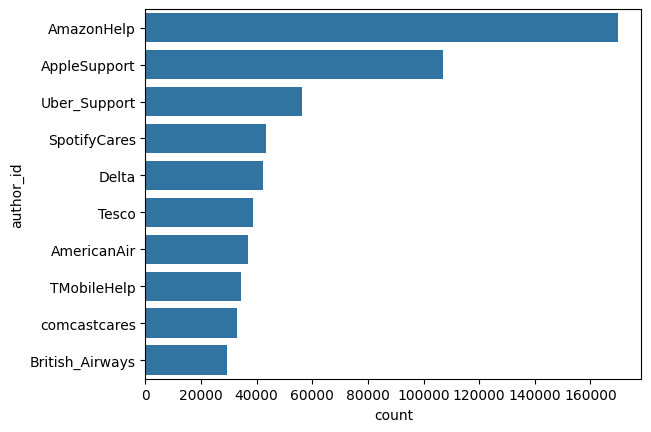

In [29]:
order = df3['author_id'].value_counts().iloc[:10].index
sns.countplot(df3['author_id'], order = order)